In [5]:

import pandas as pd
import zipfile

total_rows = 0
columns = None

# Open the ZIP and select the correct CSV
with zipfile.ZipFile(file_path, "r") as zip_file:
    with zip_file.open("flight_data_2024.csv") as csv_file:

        for chunk in pd.read_csv(
            csv_file,
            chunksize=100000
        ):
            total_rows += len(chunk)

            if columns is None:
                columns = chunk.columns.tolist()

print("Total Rows:", total_rows)
print("Total Columns:", len(columns))


/var/folders/md/9m273j410kgfzkp72k2c46800000gn/T/ipykernel_4396/197914058.py:11: DtypeWarning: Columns (24: cancellation_code) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(
/var/folders/md/9m273j410kgfzkp72k2c46800000gn/T/ipykernel_4396/197914058.py:11: DtypeWarning: Columns (24: cancellation_code) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(
/var/folders/md/9m273j410kgfzkp72k2c46800000gn/T/ipykernel_4396/197914058.py:11: DtypeWarning: Columns (24: cancellation_code) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(
/var/folders/md/9m273j410kgfzkp72k2c46800000gn/T/ipykernel_4396/197914058.py:11: DtypeWarning: Columns (24: cancellation_code) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(
/var/folders/md/9m273j410kgfzkp72k2c46800000gn/T/ipykernel_4396/197914058.py:11: Dty

Total Rows: 7079081
Total Columns: 35


/var/folders/md/9m273j410kgfzkp72k2c46800000gn/T/ipykernel_4396/197914058.py:11: DtypeWarning: Columns (24: cancellation_code) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(


In [6]:

# Count missing values in the full dataset
missing_counts = None

with zipfile.ZipFile(file_path, "r") as zip_file:
    with zip_file.open("flight_data_2024.csv") as csv_file:

        for chunk in pd.read_csv(
            csv_file,
            chunksize=100000,
            dtype={"cancellation_code": "string"}
        ):
            chunk_missing = chunk.isnull().sum()

            if missing_counts is None:
                missing_counts = chunk_missing
            else:
                missing_counts += chunk_missing

# Display columns with missing values
print("Missing Values in Full Dataset:")
print(missing_counts[missing_counts > 0])



Missing Values in Full Dataset:
op_carrier_fl_num            1
dep_time                 92659
dep_delay                92970
taxi_out                 95734
wheels_off               95734
wheels_on                97856
taxi_in                  97856
arr_time                 97854
arr_delay               113814
cancellation_code      6982766
crs_elapsed_time             1
actual_elapsed_time     113814
air_time                113814
dtype: int64


In [7]:

# Count cancelled and diverted flights
cancelled_count = 0
diverted_count = 0

with zipfile.ZipFile(file_path, "r") as zip_file:
    with zip_file.open("flight_data_2024.csv") as csv_file:

        for chunk in pd.read_csv(
            csv_file,
            chunksize=100000,
            dtype={"cancellation_code": "string"}
        ):
            cancelled_count += (chunk["cancelled"] == 1).sum()
            diverted_count += (chunk["diverted"] == 1).sum()

print("Cancelled Flights:", cancelled_count)
print("Diverted Flights:", diverted_count)


Cancelled Flights: 96315
Diverted Flights: 17499


In [8]:

# Count valid flights for departure delay prediction
valid_count = 0

with zipfile.ZipFile(file_path, "r") as zip_file:
    with zip_file.open("flight_data_2024.csv") as csv_file:

        for chunk in pd.read_csv(
            csv_file,
            chunksize=100000,
            dtype={"cancellation_code": "string"}
        ):
            valid = chunk[
                (chunk["cancelled"] == 0) &
                (chunk["dep_delay"].notna())
            ]

            valid_count += len(valid)

print("Total Flights:", total_rows)
print("Valid Flights for Prediction:", valid_count)
print("Excluded Flights:", total_rows - valid_count)


Total Flights: 7079081
Valid Flights for Prediction: 6982766
Excluded Flights: 96315


In [9]:

import pandas as pd
import zipfile
from pathlib import Path

# Output file
output_path = Path("data/flight_data_cleaned.csv")

# Remove old output if it exists
if output_path.exists():
    output_path.unlink()

first_chunk = True
cleaned_rows = 0

with zipfile.ZipFile(file_path, "r") as zip_file:
    with zip_file.open("flight_data_2024.csv") as csv_file:

        for chunk in pd.read_csv(
            csv_file,
            chunksize=100000,
            dtype={"cancellation_code": "string"}
        ):

            # Keep non-cancelled flights with known departure delay
            clean_chunk = chunk[
                (chunk["cancelled"] == 0) &
                (chunk["dep_delay"].notna())
            ].copy()

            # Create target variable
            clean_chunk["delayed"] = (
                clean_chunk["dep_delay"] >= 15
            ).astype(int)

            # Save cleaned data
            clean_chunk.to_csv(
                output_path,
                mode="a",
                header=first_chunk,
                index=False
            )

            cleaned_rows += len(clean_chunk)
            first_chunk = False

print("Cleaned Dataset Saved!")
print("Total Cleaned Rows:", cleaned_rows)
print("Output File:", output_path)


Cleaned Dataset Saved!
Total Cleaned Rows: 6982766
Output File: data/flight_data_cleaned.csv


In [10]:

# Check missing values in filtered dataset
missing_after = None

for chunk in pd.read_csv(
    output_path,
    chunksize=100000,
    dtype={"cancellation_code": "string"}
):
    chunk_missing = chunk.isnull().sum()

    if missing_after is None:
        missing_after = chunk_missing
    else:
        missing_after += chunk_missing

print("Missing Values After Filtering:")
print(missing_after[missing_after > 0])


Missing Values After Filtering:
op_carrier_fl_num            1
wheels_on                 1541
taxi_in                   1541
arr_time                  1539
arr_delay                17499
cancellation_code      6982766
actual_elapsed_time      17499
air_time                 17499
dtype: int64


In [11]:

# Select features for prediction
features = [
    "month",
    "day_of_month",
    "day_of_week",
    "op_unique_carrier",
    "origin",
    "dest",
    "crs_dep_time",
    "distance"
]

target = "delayed"

# Check selected columns
sample = pd.read_csv(
    output_path,
    nrows=5,
    usecols=features + [target]
)

print("Selected Features:", features)
print("Target:", target)
print("\nSample Data:")
display(sample)


Selected Features: ['month', 'day_of_month', 'day_of_week', 'op_unique_carrier', 'origin', 'dest', 'crs_dep_time', 'distance']
Target: delayed

Sample Data:


,month,day_of_month,day_of_week,op_unique_carrier,origin,dest,crs_dep_time,distance,delayed
0,1,1,1,9E,JFK,DTW,1252,509.0,0
1,1,1,1,9E,MSP,CLE,1015,622.0,0
2,1,1,1,9E,JFK,RIC,1415,288.0,0
3,1,1,1,9E,RIC,JFK,1650,288.0,0
4,1,1,1,9E,DTW,MKE,1015,237.0,0


In [12]:

# Count delayed and non-delayed flights
delay_counts = {0: 0, 1: 0}

for chunk in pd.read_csv(
    output_path,
    usecols=["delayed"],
    chunksize=100000
):
    counts = chunk["delayed"].value_counts()

    for label, count in counts.items():
        delay_counts[label] += count

total = sum(delay_counts.values())

print("Not Delayed:", delay_counts[0])
print("Delayed:", delay_counts[1])

print("\nPercentages:")
print("Not Delayed:", round(delay_counts[0] / total * 100, 2), "%")
print("Delayed:", round(delay_counts[1] / total * 100, 2), "%")


Not Delayed: 5541627
Delayed: 1441139

Percentages:
Not Delayed: 79.36 %
Delayed: 20.64 %


In [7]:

import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split

# Cleaned dataset path
output_path = Path("data/flight_data_cleaned.csv")

# Select features for prediction
features = [
    "month",
    "day_of_month",
    "day_of_week",
    "op_unique_carrier",
    "origin",
    "dest",
    "crs_dep_time",
    "distance"
]

# Target variable
target = "delayed"

# Load a reproducible random sample
samples = []

for chunk in pd.read_csv(
    output_path,
    usecols=features + [target],
    chunksize=100000
):
    samples.append(
        chunk.sample(frac=0.03, random_state=42)
    )

df_model = pd.concat(samples, ignore_index=True)

# Separate features and target
X = df_model[features]
y = df_model[target]

# 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Sample Size:", len(df_model))
print("Training Rows:", len(X_train))
print("Testing Rows:", len(X_test))
print("Training Delay Rate:", round(y_train.mean() * 100, 2), "%")
print("Testing Delay Rate:", round(y_test.mean() * 100, 2), "%")


Sample Size: 209483
Training Rows: 167586
Testing Rows: 41897
Training Delay Rate: 20.64 %
Testing Delay Rate: 20.64 %


In [14]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Categorical and numerical features
categorical_features = [
    "op_unique_carrier",
    "origin",
    "dest"
]

numerical_features = [
    "month",
    "day_of_month",
    "day_of_week",
    "crs_dep_time",
    "distance"
]

# Prepare categorical features
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    ))
])

# Prepare numerical features
numerical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Combine transformations
preprocessor = ColumnTransformer([
    ("categorical", categorical_transformer, categorical_features),
    ("numerical", numerical_transformer, numerical_features)
])

print("Preprocessing Pipeline Created Successfully!")
print("Categorical Features:", categorical_features)
print("Numerical Features:", numerical_features)


Preprocessing Pipeline Created Successfully!
Categorical Features: ['op_unique_carrier', 'origin', 'dest']
Numerical Features: ['month', 'day_of_month', 'day_of_week', 'crs_dep_time', 'distance']


In [15]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Create Logistic Regression pipeline
logistic_model = Pipeline([
    ("preprocessing", preprocessor),
    ("scaler", StandardScaler(with_mean=False)),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")
print("Training Rows:", len(X_train))
print("Testing Rows:", len(X_test))


Logistic Regression Model Trained Successfully!
Training Rows: 167586
Testing Rows: 41897


In [16]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Make predictions
y_pred = logistic_model.predict(X_test)

# Evaluate model
print("Logistic Regression Results")
print("---------------------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Logistic Regression Results
---------------------------
Accuracy: 0.7937
Precision: 0.507
Recall: 0.0125
F1-score: 0.0244

Classification Report:
              precision    recall  f1-score   support

           0       0.80      1.00      0.88     33249
           1       0.51      0.01      0.02      8648

    accuracy                           0.79     41897
   macro avg       0.65      0.50      0.45     41897
weighted avg       0.74      0.79      0.71     41897


Confusion Matrix:
[[33144   105]
 [ 8540   108]]


In [17]:

# Improved Logistic Regression with balanced class weights

balanced_logistic_model = Pipeline([
    ("preprocessing", preprocessor),
    ("scaler", StandardScaler(with_mean=False)),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train improved model
balanced_logistic_model.fit(X_train, y_train)

print("Balanced Logistic Regression Trained Successfully!")


Balanced Logistic Regression Trained Successfully!


In [18]:

# Evaluate Balanced Logistic Regression

y_pred_balanced = balanced_logistic_model.predict(X_test)

print("Balanced Logistic Regression Results")
print("------------------------------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred_balanced), 4))
print("Precision:", round(precision_score(y_test, y_pred_balanced, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_balanced, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred_balanced, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_balanced, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_balanced))


Balanced Logistic Regression Results
------------------------------------
Accuracy: 0.6205
Precision: 0.2988
Recall: 0.6229
F1-score: 0.4039

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.62      0.72     33249
           1       0.30      0.62      0.40      8648

    accuracy                           0.62     41897
   macro avg       0.58      0.62      0.56     41897
weighted avg       0.75      0.62      0.66     41897


Confusion Matrix:
[[20609 12640]
 [ 3261  5387]]


In [19]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create Random Forest model
random_forest_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train Random Forest
random_forest_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")


Random Forest Model Trained Successfully!


In [20]:

# Evaluate Random Forest Model

y_pred_rf = random_forest_model.predict(X_test)

print("Random Forest Results")
print("---------------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_rf, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred_rf, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))


Random Forest Results
---------------------
Accuracy: 0.6333
Precision: 0.3111
Recall: 0.6395
F1-score: 0.4185

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.63      0.73     33249
           1       0.31      0.64      0.42      8648

    accuracy                           0.63     41897
   macro avg       0.59      0.64      0.58     41897
weighted avg       0.76      0.63      0.67     41897


Confusion Matrix:
[[21002 12247]
 [ 3118  5530]]


Top 15 Important Features:


,Feature,Importance
705,numerical__crs_dep_time,0.389256
702,numerical__month,0.126931
14,categorical__op_unique_carrier_YX,0.044775
704,numerical__day_of_week,0.035502
1,categorical__op_unique_carrier_AA,0.034728
703,numerical__day_of_month,0.033489
706,numerical__distance,0.027935
13,categorical__op_unique_carrier_WN,0.022461
4,categorical__op_unique_carrier_DL,0.019675
104,categorical__origin_DFW,0.019560


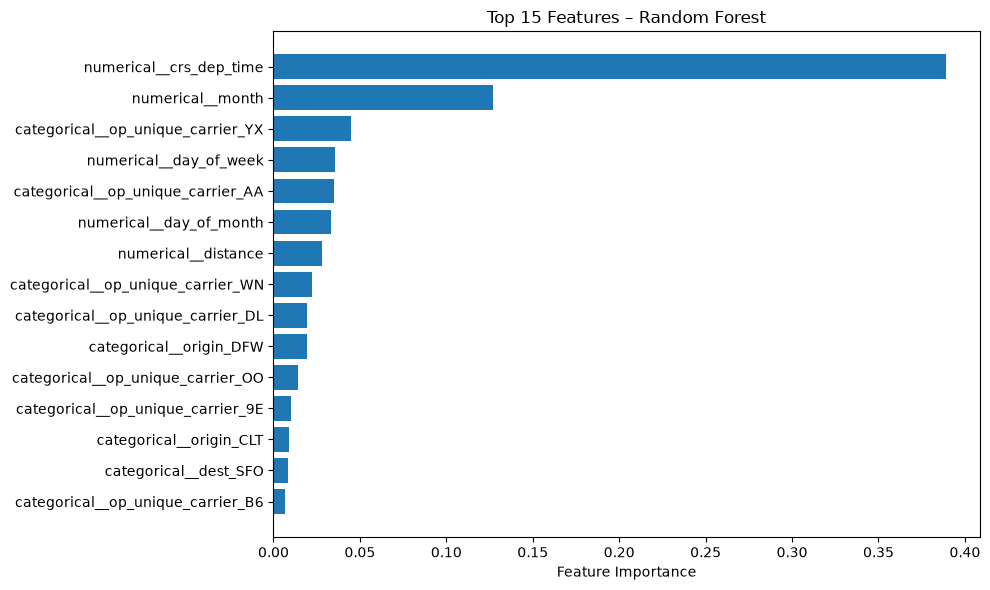

In [21]:

import pandas as pd
import matplotlib.pyplot as plt

# Get feature names after preprocessing
feature_names = random_forest_model.named_steps[
    "preprocessing"
].get_feature_names_out()

# Get feature importance
importances = random_forest_model.named_steps[
    "classifier"
].feature_importances_

# Create feature importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Show top 15 features
top_features = importance_df.sort_values(
    by="Importance",
    ascending=False
).head(15)

print("Top 15 Important Features:")
display(top_features)

# Plot
plt.figure(figsize=(10, 6))
plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.title("Top 15 Features – Random Forest")
plt.tight_layout()
plt.show()


In [22]:

# Improved Random Forest Model

improved_rf_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=150,
        max_depth=25,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train improved model
improved_rf_model.fit(X_train, y_train)

print("Improved Random Forest Trained Successfully!")


Improved Random Forest Trained Successfully!


In [23]:

# Evaluate Improved Random Forest

y_pred_improved = improved_rf_model.predict(X_test)

print("Improved Random Forest Results")
print("--------------------------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred_improved), 4))
print("Precision:", round(precision_score(y_test, y_pred_improved, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_improved, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred_improved, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_improved, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_improved))


Improved Random Forest Results
--------------------------------
Accuracy: 0.6384
Precision: 0.3153
Recall: 0.642
F1-score: 0.4229

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.64      0.74     33249
           1       0.32      0.64      0.42      8648

    accuracy                           0.64     41897
   macro avg       0.59      0.64      0.58     41897
weighted avg       0.76      0.64      0.67     41897


Confusion Matrix:
[[21195 12054]
 [ 3096  5552]]


In [24]:

import joblib
from pathlib import Path

# Create models folder
models_path = Path("models")
models_path.mkdir(exist_ok=True)

# Save trained model
model_file = models_path / "flight_delay_rf_model.pkl"

joblib.dump(improved_rf_model, model_file)

print("Model Saved Successfully!")
print("Model Path:", model_file)
print("File Size (MB):", round(
    model_file.stat().st_size / (1024 * 1024), 2
))


Model Saved Successfully!
Model Path: models/flight_delay_rf_model.pkl
File Size (MB): 10.74


In [11]:

from sklearn.metrics import precision_score, recall_score, f1_score

# Predict delay probabilities
probabilities = improved_rf_model.predict_proba(X_test)[:, 1]

# Compare different thresholds
for threshold in [0.45, 0.47, 0.49, 0.51, 0.53, 0.55]:
    predictions = (probabilities >= threshold).astype(int)

    print(
        f"Threshold: {threshold} | "
        f"Precision: {precision_score(y_test, predictions):.4f} | "
        f"Recall: {recall_score(y_test, predictions):.4f} | "
        f"F1: {f1_score(y_test, predictions):.4f}"
    )


Threshold: 0.45 | Precision: 0.2708 | Recall: 0.8091 | F1: 0.4058
Threshold: 0.47 | Precision: 0.2878 | Recall: 0.7480 | F1: 0.4157
Threshold: 0.49 | Precision: 0.3047 | Recall: 0.6783 | F1: 0.4205
Threshold: 0.51 | Precision: 0.3236 | Recall: 0.5979 | F1: 0.4199
Threshold: 0.53 | Precision: 0.3471 | Recall: 0.5151 | F1: 0.4147
Threshold: 0.55 | Precision: 0.3708 | Recall: 0.4235 | F1: 0.3954


In [2]:

import joblib

improved_rf_model = joblib.load(
    "models/flight_delay_rf_model.pkl"
)

print("Model loaded successfully!")


Model loaded successfully!


In [9]:

print("X_test exists:", "X_test" in globals())
print("y_test exists:", "y_test" in globals())


X_test exists: True
y_test exists: True


In [4]:
from pathlib import Path

output_path = Path("data/flight_data_cleaned.csv")

print("File exists:", output_path.exists())

File exists: True


In [12]:
print(pd.read_csv(output_path, nrows=0).columns.tolist())

['year', 'month', 'day_of_month', 'day_of_week', 'fl_date', 'op_unique_carrier', 'op_carrier_fl_num', 'origin', 'origin_city_name', 'origin_state_nm', 'dest', 'dest_city_name', 'dest_state_nm', 'crs_dep_time', 'dep_time', 'dep_delay', 'taxi_out', 'wheels_off', 'wheels_on', 'taxi_in', 'crs_arr_time', 'arr_time', 'arr_delay', 'cancelled', 'cancellation_code', 'diverted', 'crs_elapsed_time', 'actual_elapsed_time', 'air_time', 'distance', 'carrier_delay', 'weather_delay', 'nas_delay', 'security_delay', 'late_aircraft_delay', 'delayed']


In [13]:

dates = pd.read_csv(
    output_path,
    usecols=["fl_date"],
    parse_dates=["fl_date"]
)

print("First Flight:", dates["fl_date"].min())
print("Last Flight:", dates["fl_date"].max())


First Flight: 2024-01-01 00:00:00
Last Flight: 2024-12-31 00:00:00


In [14]:

# Count flights in each time period
date_values = pd.to_datetime(dates["fl_date"])

train_period = date_values < "2024-10-01"
test_period = date_values >= "2024-10-01"

print("January–September:", train_period.sum())
print("October–December:", test_period.sum())


January–September: 5214348
October–December: 1768418


In [2]:

import pandas as pd
from pathlib import Path

output_path = Path("data/flight_data_cleaned.csv")

features = [
    "month",
    "day_of_month",
    "day_of_week",
    "op_unique_carrier",
    "origin",
    "dest",
    "crs_dep_time",
    "distance"
]

target = "delayed"

# Prepare time-based training and testing samples
train_samples = []
test_samples = []

for chunk in pd.read_csv(
    output_path,
    usecols=features + [target, "fl_date"],
    chunksize=100000
):
    chunk["fl_date"] = pd.to_datetime(chunk["fl_date"])

    train_chunk = chunk[chunk["fl_date"] < "2024-10-01"]
    test_chunk = chunk[chunk["fl_date"] >= "2024-10-01"]

    if len(train_chunk) > 0:
        train_samples.append(
            train_chunk.sample(frac=0.06, random_state=42)
        )

    if len(test_chunk) > 0:
        test_samples.append(
            test_chunk.sample(frac=0.06, random_state=42)
        )

train_df = pd.concat(train_samples, ignore_index=True)
test_df = pd.concat(test_samples, ignore_index=True)

print("Training Sample:", len(train_df))
print("Testing Sample:", len(test_df))


Training Sample: 312861
Testing Sample: 106105


In [16]:

# Time-based training data
X_train_time = train_df[features]
y_train_time = train_df[target]

# Time-based testing data
X_test_time = test_df[features]
y_test_time = test_df[target]

print("Training:", X_train_time.shape)
print("Testing:", X_test_time.shape)

print("Training Delay Rate:", round(y_train_time.mean() * 100, 2), "%")
print("Testing Delay Rate:", round(y_test_time.mean() * 100, 2), "%")


Training: (156430, 8)
Testing: (53053, 8)
Training Delay Rate: 21.95 %
Testing Delay Rate: 16.78 %


In [17]:

from sklearn.base import clone

# Create a new model with the same settings
time_rf_model = clone(improved_rf_model)

# Train only on January–September flights
time_rf_model.fit(X_train_time, y_train_time)

print("Time-Based Random Forest Training Completed!")


Time-Based Random Forest Training Completed!


In [18]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Predict on October–December flights
y_pred_time = time_rf_model.predict(X_test_time)

# Evaluate model
print("Time-Based Random Forest Results")
print("--------------------------------")
print("Accuracy:", round(accuracy_score(y_test_time, y_pred_time) * 100, 2), "%")
print("Precision:", round(precision_score(y_test_time, y_pred_time, zero_division=0) * 100, 2), "%")
print("Recall:", round(recall_score(y_test_time, y_pred_time) * 100, 2), "%")
print("F1-Score:", round(f1_score(y_test_time, y_pred_time) * 100, 2), "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_time, y_pred_time))


Time-Based Random Forest Results
--------------------------------
Accuracy: 72.13 %
Precision: 27.17 %
Recall: 39.34 %
F1-Score: 32.14 %

Confusion Matrix:
[[34763  9388]
 [ 5400  3502]]


In [19]:

# Get delay probabilities
time_probabilities = time_rf_model.predict_proba(X_test_time)[:, 1]

# Compare thresholds
for threshold in [0.30, 0.35, 0.40, 0.45, 0.50]:
    predictions = (time_probabilities >= threshold).astype(int)

    print(
        f"Threshold: {threshold} | "
        f"Precision: {precision_score(y_test_time, predictions, zero_division=0):.4f} | "
        f"Recall: {recall_score(y_test_time, predictions):.4f} | "
        f"F1: {f1_score(y_test_time, predictions):.4f}"
    )


Threshold: 0.3 | Precision: 0.1714 | Recall: 0.9878 | F1: 0.2921
Threshold: 0.35 | Precision: 0.1876 | Recall: 0.9193 | F1: 0.3116
Threshold: 0.4 | Precision: 0.2085 | Recall: 0.7915 | F1: 0.3300
Threshold: 0.45 | Precision: 0.2310 | Recall: 0.6367 | F1: 0.3390
Threshold: 0.5 | Precision: 0.2717 | Recall: 0.3934 | F1: 0.3214


In [20]:
print("Preprocessing:", time_rf_model.named_steps.keys())

Preprocessing: dict_keys(['preprocessing', 'classifier'])


In [24]:


from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.base import clone
from sklearn.preprocessing import FunctionTransformer

# Convert sparse data to dense
def to_dense(X):
    return X.toarray() if hasattr(X, "toarray") else X

# Create new model
hgb_model = Pipeline([
    (
        "preprocessing",
        clone(time_rf_model.named_steps["preprocessing"])
    ),
    (
        "to_dense",
        FunctionTransformer(to_dense)
    ),
    (
        "classifier",
       
HistGradientBoostingClassifier(
    max_iter=150,
    learning_rate=0.1,
    max_leaf_nodes=31,
    class_weight="balanced",
    random_state=42
)

    )
])

# Train the model
hgb_model.fit(X_train_time, y_train_time)

print("HistGradientBoosting Training Completed!")


HistGradientBoosting Training Completed!


In [25]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Predict using HistGradientBoosting
hgb_predictions = hgb_model.predict(X_test_time)

# Evaluate model
print("HistGradientBoosting Results")
print("--------------------------------")

print("Accuracy:", round(accuracy_score(y_test_time, hgb_predictions) * 100, 2), "%")
print("Precision:", round(precision_score(y_test_time, hgb_predictions, zero_division=0) * 100, 2), "%")
print("Recall:", round(recall_score(y_test_time, hgb_predictions) * 100, 2), "%")
print("F1-Score:", round(f1_score(y_test_time, hgb_predictions) * 100, 2), "%")


HistGradientBoosting Results
--------------------------------
Accuracy: 75.53 %
Precision: 29.3 %
Recall: 32.43 %
F1-Score: 30.78 %


In [26]:

# Get Balanced HGB probabilities
hgb_probabilities = hgb_model.predict_proba(X_test_time)[:, 1]

# Compare different thresholds
for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55]:
    predictions = (hgb_probabilities >= threshold).astype(int)

    print(
        f"Threshold: {threshold} | "
        f"Precision: {precision_score(y_test_time, predictions, zero_division=0):.4f} | "
        f"Recall: {recall_score(y_test_time, predictions):.4f} | "
        f"F1: {f1_score(y_test_time, predictions):.4f}"
    )


Threshold: 0.3 | Precision: 0.2088 | Recall: 0.8060 | F1: 0.3317
Threshold: 0.35 | Precision: 0.2250 | Recall: 0.6998 | F1: 0.3405
Threshold: 0.4 | Precision: 0.2421 | Recall: 0.5667 | F1: 0.3393
Threshold: 0.45 | Precision: 0.2669 | Recall: 0.4371 | F1: 0.3315
Threshold: 0.5 | Precision: 0.2930 | Recall: 0.3243 | F1: 0.3078
Threshold: 0.55 | Precision: 0.3133 | Recall: 0.2184 | F1: 0.2574


In [27]:

from sklearn.model_selection import train_test_split

# Split January–September into training and validation
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train_time,
    y_train_time,
    test_size=0.2,
    random_state=42,
    stratify=y_train_time
)

print("Training:", X_train_final.shape)
print("Validation:", X_val.shape)


Training: (125144, 8)
Validation: (31286, 8)


In [28]:

from sklearn.base import clone

# Create a fresh Random Forest model
rf_validation_model = clone(time_rf_model)

# Train using training data only
rf_validation_model.fit(X_train_final, y_train_final)

print("Random Forest Validation Model Trained Successfully!")


Random Forest Validation Model Trained Successfully!


In [29]:

from sklearn.base import clone

# Create a fresh Balanced HGB model
hgb_validation_model = clone(hgb_model)

# Train using the same training data
hgb_validation_model.fit(X_train_final, y_train_final)

print("Balanced HGB Validation Model Trained Successfully!")


Balanced HGB Validation Model Trained Successfully!


In [30]:

from sklearn.metrics import precision_score, recall_score, f1_score

# Models to compare
models = {
    "Random Forest": rf_validation_model,
    "Balanced HGB": hgb_validation_model
}

# Compare models on validation data
for name, model in models.items():
    probabilities = model.predict_proba(X_val)[:, 1]

    print("\nModel:", name)

    for threshold in [0.30, 0.35, 0.40, 0.45, 0.50]:
        predictions = (probabilities >= threshold).astype(int)

        print(
            f"Threshold: {threshold} | "
            f"Precision: {precision_score(y_val, predictions, zero_division=0):.4f} | "
            f"Recall: {recall_score(y_val, predictions):.4f} | "
            f"F1: {f1_score(y_val, predictions):.4f}"
        )



Model: Random Forest
Threshold: 0.3 | Precision: 0.2205 | Recall: 0.9997 | F1: 0.3613
Threshold: 0.35 | Precision: 0.2273 | Recall: 0.9889 | F1: 0.3697
Threshold: 0.4 | Precision: 0.2536 | Recall: 0.9290 | F1: 0.3985
Threshold: 0.45 | Precision: 0.2892 | Recall: 0.8121 | F1: 0.4265
Threshold: 0.5 | Precision: 0.3314 | Recall: 0.6493 | F1: 0.4388

Model: Balanced HGB
Threshold: 0.3 | Precision: 0.2562 | Recall: 0.9304 | F1: 0.4017
Threshold: 0.35 | Precision: 0.2759 | Recall: 0.8885 | F1: 0.4210
Threshold: 0.4 | Precision: 0.2973 | Recall: 0.8246 | F1: 0.4371
Threshold: 0.45 | Precision: 0.3229 | Recall: 0.7428 | F1: 0.4501
Threshold: 0.5 | Precision: 0.3516 | Recall: 0.6540 | F1: 0.4573


In [3]:

# Prepare training and testing data
X_train_time = train_df[features]
y_train_time = train_df[target]

X_test_time = test_df[features]
y_test_time = test_df[target]

# Split training data into Training and Validation
from sklearn.model_selection import train_test_split

X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train_time,
    y_train_time,
    test_size=0.2,
    random_state=42,
    stratify=y_train_time
)

print("Training:", len(X_train_final))
print("Validation:", len(X_val))
print("Testing:", len(X_test_time))


Training: 250288
Validation: 62573
Testing: 106105


In [4]:

from sklearn.base import clone
import joblib

# Load original model settings
original_model = joblib.load(
    "models/flight_delay_rf_model.pkl"
)

# Create a fresh Random Forest model
rf_validation_model = clone(original_model)

# Train on the larger training dataset
rf_validation_model.fit(X_train_final, y_train_final)

print("Random Forest Training Completed!")
print("Training Records:", len(X_train_final))


Random Forest Training Completed!
Training Records: 250288


In [5]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Predict on validation data
rf_predictions = rf_validation_model.predict(X_val)

print("Random Forest - Larger Dataset")
print("--------------------------------")
print("Accuracy:", round(accuracy_score(y_val, rf_predictions) * 100, 2), "%")
print("Precision:", round(precision_score(y_val, rf_predictions, zero_division=0) * 100, 2), "%")
print("Recall:", round(recall_score(y_val, rf_predictions) * 100, 2), "%")
print("F1-Score:", round(f1_score(y_val, rf_predictions) * 100, 2), "%")


Random Forest - Larger Dataset
--------------------------------
Accuracy: 64.08 %
Precision: 33.65 %
Recall: 65.09 %
F1-Score: 44.36 %


In [7]:

from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import FunctionTransformer

# Convert sparse data to dense
def to_dense(X):
    return X.toarray() if hasattr(X, "toarray") else X

# Create Balanced HGB model
hgb_validation_model = Pipeline([
    ("preprocessing", rf_validation_model.named_steps["preprocessing"]),
    ("to_dense", FunctionTransformer(to_dense)),
    ("classifier", HistGradientBoostingClassifier(
        class_weight="balanced",
        random_state=42
    ))
])

print("Balanced HGB Model Created!")



Balanced HGB Model Created!


In [8]:

# Train Balanced HGB
hgb_validation_model.fit(X_train_final, y_train_final)

print("Balanced HGB Training Completed!")
print("Training Records:", len(X_train_final))


Balanced HGB Training Completed!
Training Records: 250288


In [9]:

# Predict using Balanced HGB
hgb_predictions = hgb_validation_model.predict(X_val)

print("Balanced HGB - Larger Dataset")
print("--------------------------------")
print("Accuracy:", round(accuracy_score(y_val, hgb_predictions) * 100, 2), "%")
print("Precision:", round(precision_score(y_val, hgb_predictions, zero_division=0) * 100, 2), "%")
print("Recall:", round(recall_score(y_val, hgb_predictions) * 100, 2), "%")
print("F1-Score:", round(f1_score(y_val, hgb_predictions) * 100, 2), "%")


Balanced HGB - Larger Dataset
--------------------------------
Accuracy: 66.04 %
Precision: 35.34 %
Recall: 65.45 %
F1-Score: 45.89 %


In [10]:

from sklearn.metrics import precision_score, recall_score, f1_score

# Get probabilities from Balanced HGB
hgb_probs = hgb_validation_model.predict_proba(X_val)[:, 1]

# Test different thresholds
for threshold in [0.40, 0.45, 0.50, 0.55, 0.60, 0.65]:
    predictions = (hgb_probs >= threshold).astype(int)

    print(
        f"Threshold: {threshold} | "
        f"Precision: {precision_score(y_val, predictions):.4f} | "
        f"Recall: {recall_score(y_val, predictions):.4f} | "
        f"F1: {f1_score(y_val, predictions):.4f}"
    )


Threshold: 0.4 | Precision: 0.3003 | Recall: 0.8156 | F1: 0.4390
Threshold: 0.45 | Precision: 0.3248 | Recall: 0.7398 | F1: 0.4514
Threshold: 0.5 | Precision: 0.3534 | Recall: 0.6545 | F1: 0.4589
Threshold: 0.55 | Precision: 0.3854 | Recall: 0.5631 | F1: 0.4576
Threshold: 0.6 | Precision: 0.4254 | Recall: 0.4660 | F1: 0.4448
Threshold: 0.65 | Precision: 0.4714 | Recall: 0.3524 | F1: 0.4033


In [11]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Final test on October-December data
hgb_test_probs = hgb_validation_model.predict_proba(X_test_time)[:, 1]

hgb_test_predictions = (hgb_test_probs >= 0.50).astype(int)

print("Balanced HGB - Final Test Results")
print("--------------------------------")
print("Testing Records:", len(X_test_time))
print("Accuracy:", round(accuracy_score(y_test_time, hgb_test_predictions) * 100, 2), "%")
print("Precision:", round(precision_score(y_test_time, hgb_test_predictions, zero_division=0) * 100, 2), "%")
print("Recall:", round(recall_score(y_test_time, hgb_test_predictions, zero_division=0) * 100, 2), "%")
print("F1-Score:", round(f1_score(y_test_time, hgb_test_predictions, zero_division=0) * 100, 2), "%")

print("Confusion Matrix:")
print(confusion_matrix(y_test_time, hgb_test_predictions))


Balanced HGB - Final Test Results
--------------------------------
Testing Records: 106105
Accuracy: 76.35 %
Precision: 29.42 %
Recall: 29.75 %
F1-Score: 29.58 %
Confusion Matrix:
[[75743 12647]
 [12444  5271]]


In [12]:

# Final Test - Random Forest
rf_test_predictions = rf_validation_model.predict(X_test_time)

print("Random Forest - Final Test Results")
print("--------------------------------")
print("Testing Records:", len(X_test_time))
print("Accuracy:", round(accuracy_score(y_test_time, rf_test_predictions) * 100, 2), "%")
print("Precision:", round(precision_score(y_test_time, rf_test_predictions, zero_division=0) * 100, 2), "%")
print("Recall:", round(recall_score(y_test_time, rf_test_predictions, zero_division=0) * 100, 2), "%")
print("F1-Score:", round(f1_score(y_test_time, rf_test_predictions, zero_division=0) * 100, 2), "%")

print("Confusion Matrix:")
print(confusion_matrix(y_test_time, rf_test_predictions))


Random Forest - Final Test Results
--------------------------------
Testing Records: 106105
Accuracy: 72.56 %
Precision: 27.04 %
Recall: 37.89 %
F1-Score: 31.56 %
Confusion Matrix:
[[70280 18110]
 [11002  6713]]


In [13]:

print("Training Delay Rate:",
      round(y_train_final.mean() * 100, 2), "%")

print("Validation Delay Rate:",
      round(y_val.mean() * 100, 2), "%")

print("Final Test Delay Rate:",
      round(y_test_time.mean() * 100, 2), "%")


Training Delay Rate: 22.0 %
Validation Delay Rate: 22.0 %
Final Test Delay Rate: 16.7 %


In [14]:

# Check delay rate by month
monthly_delay = pd.concat([
    train_df[["month", "delayed"]],
    test_df[["month", "delayed"]]
])

monthly_results = monthly_delay.groupby("month").agg(
    total_flights=("delayed", "size"),
    delay_rate=("delayed", "mean")
)

monthly_results["delay_rate"] = (
    monthly_results["delay_rate"] * 100
).round(2)

print(monthly_results)


       total_flights  delay_rate
month                           
1              31622       22.93
2              31046       15.41
3              35134       20.49
4              34691       19.04
5              36086       25.65
6              36208       25.31
7              36960       29.18
8              36398       23.27
9              34716       15.34
10             36582       13.73
11             34343       14.57
12             35180       21.85


In [15]:

from sklearn.metrics import f1_score, recall_score

# Evaluate Random Forest by test month
monthly_test = test_df[["month"]].copy()

monthly_test["actual"] = y_test_time.to_numpy()
monthly_test["predicted"] = rf_test_predictions

for month in [10, 11, 12]:
    data = monthly_test[monthly_test["month"] == month]

    print(f"Month: {month}")
    print("Records:", len(data))
    print("Recall:", round(recall_score(
        data["actual"], data["predicted"]
    ) * 100, 2), "%")
    print("F1-Score:", round(f1_score(
        data["actual"], data["predicted"]
    ) * 100, 2), "%")
    print("--------------------")


Month: 10
Records: 36582
Recall: 39.63 %
F1-Score: 29.57 %
--------------------
Month: 11
Records: 34343
Recall: 36.94 %
F1-Score: 28.2 %
--------------------
Month: 12
Records: 35180
Recall: 37.38 %
F1-Score: 36.0 %
--------------------


In [16]:

import joblib
from pathlib import Path

# Save updated Random Forest model
model_path = Path("models/flight_delay_rf_model_updated.pkl")

joblib.dump(rf_validation_model, model_path)

print("Updated Random Forest Model Saved!")
print("Model Path:", model_path)
print("File Size (MB):", round(
    model_path.stat().st_size / (1024 * 1024), 2
))


Updated Random Forest Model Saved!
Model Path: models/flight_delay_rf_model_updated.pkl
File Size (MB): 15.42
